# 실습 05 · 평가·오류 이미지 분석

> **Day14 | 전이학습·오류 분석 · 01_기본필수**
> 원본 스크립트: `05_errors.py` · 교안 PPT 57쪽 · 직접 구현: B05
> 코드: 완성 정답 기준(주석본 `01_기본필수_주석/05_errors.py`와 같은 로직) · 결과: 이 노트북을 실제 실행한 출력

Head를 1회만 학습한 초기 모델로 혼동행렬을 만들고, 오답 이미지의 실제·예측·확률로 관찰과 가설을 나눈다.

## 학습 목표

- 혼동행렬의 행=실제, 열=예측 규칙을 지킨다.
- 분류 보고서로 어떤 클래스가 어디로 틀리는지 읽는다.
- 오답 이미지를 직접 보고 관찰과 가설을 구분한다.

## 핵심 개념

| 개념 | 설명 |
|---|---|
| `confusion_matrix(y_true, y_pred, labels)` | 인자 순서가 (실제, 예측)이어야 행=실제가 된다. |
| 초기 모델 | 1 epoch만 학습한 오류 관찰용 모델. 07 최종 모델과 다르다. |
| 관찰 / 가설 | 관찰은 측정·이미지에서 본 사실, 가설은 아직 검증하지 않은 설명이다. |
| 오답 0건 | 오답이 없으면 그대로 보고하고 억지로 만들지 않는다. |

## 0. 준비

- 필요한 패키지: `torch`, `torchvision`, `numpy`, `pandas`, `scikit-learn`, `opencv-python`(또는 headless), `Pillow`
- 이 노트북은 `01_기본필수` 폴더(같은 폴더에 `data/`가 있는 위치)에서 연다.
- 입력은 `data/`의 원본을 읽기만 하고, 노트북이 만드는 결과 파일은 `outputs_notebook/`에 저장한다.
- CPU에서 실행한다. GPU·CUDA 코드는 없다.

In [1]:
# ============================================================
# 0. 라이브러리·경로·재현 설정
# ============================================================

# Path: 노트북 폴더 기준 경로 계산
from pathlib import Path
# json: 지표 딕셔너리를 JSON 문자열로 변환
import json
# NumPy: 배열 계산과 npz 가중치 읽기
import numpy as np
# pandas: 결과 표 출력·CSV 저장
import pandas as pd
# PyTorch: Tensor 연산과 모델 학습
import torch
# nn: 층(Conv2d·Linear)과 손실 함수
from torch import nn
# ImageFolder: data/분할/클래스 폴더를 데이터셋으로 읽기
from torchvision.datasets import ImageFolder
# transforms: 크기 변경·Tensor 변환
from torchvision import transforms as tr
# sklearn.metrics: 정확도·F1·분류 보고서·혼동행렬
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# set_num_threads(1) : CPU 연산 순서 고정 -> 재현에 유리
torch.set_num_threads(1)
# manual_seed(14) : 난수 시작값 고정 -> 같은 Head 초기값
torch.manual_seed(14)
# BASE : 노트북을 연 폴더(01_기본필수), DATA : 입력 폴더
BASE = Path.cwd()
DATA = BASE / "data"
# OUT : 노트북 결과 저장 폴더(원본 폴더와 분리)
OUT = BASE / "outputs_notebook"
OUT.mkdir(exist_ok=True)

# tr.Resize((32, 32)) : 40×40 원본 -> 32×32
# tr.ToTensor()       : [H,W,C] 0~255 -> [C,H,W] 0.0~1.0
# 주의: ImageNet용 Resize256·CenterCrop224·Normalize와 섞지 않음
transform = tr.Compose([tr.Resize((32, 32)), tr.ToTensor()])
print("입력 폴더:", DATA.name, "/ 결과 폴더:", OUT.name)

입력 폴더: data / 결과 폴더: outputs_notebook


In [2]:
# OpenCV: 열지도 색 입히기·합성·PNG 저장
import cv2
# IPython.display: 저장한 PNG를 노트북 안에 표시
from IPython.display import Image, display

In [3]:
# ============================================================
# 1. train·valid 이미지 읽기
# ============================================================

# ImageFolder(root, transform) : 폴더 이름=클래스, 꺼낼 때 transform 적용
# 주의: test는 읽지 않음(최종 평가용으로 보존)
train = ImageFolder(DATA / "train", transform=transform)
valid = ImageFolder(DATA / "valid", transform=transform)

# torch.stack : 이미지들을 한 묶음으로 -> [N, 3, 32, 32]
X_train = torch.stack([train[i][0] for i in range(len(train))])
# 라벨 목록 -> 정수 Tensor [N] (CrossEntropyLoss 형식)
y_train = torch.tensor(train.targets, dtype=torch.long)
X_valid = torch.stack([valid[i][0] for i in range(len(valid))])
y_valid = torch.tensor(valid.targets, dtype=torch.long)
print("X_train:", tuple(X_train.shape), "X_valid:", tuple(X_valid.shape))
print("train 개수:", [train.targets.count(i) for i in range(3)], "valid 개수:", [valid.targets.count(i) for i in range(3)])

X_train: (21, 3, 32, 32) X_valid: (9, 3, 32, 32)
train 개수: [12, 6, 3] valid 개수: [3, 3, 3]


In [4]:
# ============================================================
# 2. 모델 구성·source Backbone 적용
# ============================================================

def build_source_model():
    """source Backbone을 적용한 TinyShapeCNN을 만든다.

    - 0~8번 층: source_backbone.npz 값으로 교체(합성 도형 사전학습 Backbone)
    - 9번 층 : Linear(256, 3) 새 Head, 무작위 초기값 유지
    """
    # 0~8 Backbone, 9 Head / 입력 [N,3,32,32] -> 출력 [N,3]
    model = nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
        nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(256, 3),
    )
    # allow_pickle=False : 숫자 배열만 허용하는 안전한 읽기
    # state.update(...)  : npz에 있는 Backbone 키만 교체
    with np.load(DATA / "source_backbone.npz", allow_pickle=False) as saved:
        state = model.state_dict()
        state.update({name: torch.from_numpy(saved[name].copy()) for name in saved.files})
    model.load_state_dict(state)
    return model

In [5]:
# ============================================================
# 3. Head-only 설정
# ============================================================

model = build_source_model()
# 전체 잠금 -> Head(9번)만 열기 : 256×3 + 3 = 771개
for p in model.parameters():
    p.requires_grad = False
for p in model[9].parameters():
    p.requires_grad = True
# eval() : BN running 통계 고정(gradient는 끄지 않음)
model.eval()
# AdamW : Head만 전달, lr=0.01 : 학습률, weight_decay=0.0 : 감쇠 없음
optimizer = torch.optim.AdamW(model[9].parameters(), lr=0.01, weight_decay=0.0)
criterion = nn.CrossEntropyLoss()
print("학습 파라미터:", sum(p.numel() for p in model.parameters() if p.requires_grad))

학습 파라미터: 771


In [6]:
# ============================================================
# 4. 초기 모델 1회 학습과 valid 예측
# ============================================================

# 오류 관찰용 1 epoch 학습(07번 최종 8회 학습 모델과 구분)
for epoch in range(1):
    # zero_grad -> 손실 -> backward -> step
    optimizer.zero_grad()
    loss = criterion(model(X_train), y_train)
    loss.backward()
    optimizer.step()

with torch.no_grad():
    # logits [9, 3] -> softmax(dim=1) 확률, argmax(dim=1) 예측
    logits = model(X_valid)
    probabilities = logits.softmax(dim=1)
    predictions = logits.argmax(dim=1)

# 확률 표: 파일별 클래스 확률·예측 확인
table = pd.DataFrame(probabilities.numpy().round(3), columns=valid.classes)
table.insert(0, "file", [Path(p).name for p, _ in valid.samples])
table["actual"] = [valid.classes[i] for i in y_valid]
table["predicted"] = [valid.classes[i] for i in predictions]
table

,file,circle,square,triangle,actual,predicted
0,circle_000.png,0.890,0.060,0.050,circle,circle
1,circle_001.png,0.876,0.091,0.033,circle,circle
2,circle_002.png,0.909,0.070,0.020,circle,circle
3,square_000.png,0.311,0.662,0.027,square,square
4,square_001.png,0.297,0.643,0.060,square,square
5,square_002.png,0.584,0.367,0.049,square,circle
6,triangle_000.png,0.663,0.199,0.138,triangle,circle
7,triangle_001.png,0.479,0.192,0.329,triangle,circle
8,triangle_002.png,0.632,0.245,0.123,triangle,circle


## 5. 혼동행렬 (TODO B05)

원본 TODO는 0으로 채운 빈 행렬이었다.

In [7]:
# ============================================================
# 5. 혼동행렬 (TODO B05)
# ============================================================

# y_true=y_valid(행), y_pred=predictions(열), labels 순서 고정
matrix = confusion_matrix(y_valid, predictions, labels=[0, 1, 2])
print("혼동행렬:\n", matrix)
print(classification_report(y_valid, predictions, labels=[0, 1, 2], target_names=valid.classes, zero_division=0, digits=3))
cm = pd.DataFrame(matrix, index=[f"actual_{c}" for c in valid.classes], columns=[f"pred_{c}" for c in valid.classes])
cm.to_csv(OUT / "p05_confusion.csv")
cm

혼동행렬:
 [[3 0 0]
 [1 2 0]
 [3 0 0]]
              precision    recall  f1-score   support

      circle      0.429     1.000     0.600         3
      square      1.000     0.667     0.800         3
    triangle      0.000     0.000     0.000         3

    accuracy                          0.556         9
   macro avg      0.476     0.556     0.467         9
weighted avg      0.476     0.556     0.467         9



,pred_circle,pred_square,pred_triangle
actual_circle,3,0,0
actual_square,1,2,0
actual_triangle,3,0,0


## 6. 오답 목록과 이미지

오답 파일·실제·예측·확률을 기록하고 이미지를 직접 본다.

오답 개수: 4
square_002.png 실제: square 예측: circle
triangle_000.png 실제: triangle 예측: circle
triangle_001.png 실제: triangle 예측: circle


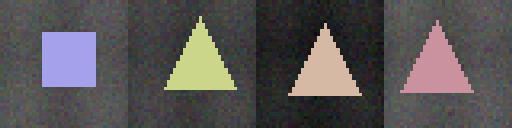

,file,circle,square,triangle,actual,predicted
5,square_002.png,0.584,0.367,0.049,square,circle
6,triangle_000.png,0.663,0.199,0.138,triangle,circle
7,triangle_001.png,0.479,0.192,0.329,triangle,circle
8,triangle_002.png,0.632,0.245,0.123,triangle,circle


In [8]:
# ============================================================
# 6. 오답 목록과 이미지
# ============================================================

# (predictions != y_valid) -> nonzero() -> flatten() -> tolist() : 오답 위치 리스트
errors = (predictions != y_valid).nonzero().flatten().tolist()
print("오답 개수:", len(errors))
for i in errors[:3]:
    print(Path(valid.samples[i][0]).name, "실제:", valid.classes[y_valid[i]], "예측:", valid.classes[predictions[i]])

error_table = table.iloc[errors]
error_table.to_csv(OUT / "p05_errors.csv", index=False)

# 오답 이미지를 가로로 붙여 저장(원본 40×40 -> 128×128 확대, 최근접 보간)
if errors:
    tiles = [cv2.resize(cv2.imread(valid.samples[i][0]), (128, 128), interpolation=cv2.INTER_NEAREST) for i in errors]
    cv2.imwrite(str(OUT / "p05_error_images.png"), np.hstack(tiles))
    display(Image(filename=str(OUT / "p05_error_images.png")))
else:
    print("오답 0건: 이미지를 만들지 않음")
error_table

## 7. 관찰과 가설 (square_002.png)

| 구분 | 내용 |
|---|---|
| 관찰 | 실제 square, 예측 circle, 확률 circle 0.584 / square 0.367 |
| 관찰 | 다른 square 두 장보다 도형이 작고 배경이 밝다 |
| 가설 | 도형 면적이 작아 특징이 circle 쪽과 비슷해졌을 수 있다(미검증) |
| 가설 | 초기 Head가 train 다수 클래스 circle 쪽으로 기울어 있다(9장 중 7장을 circle로 예측) |

## 정리

- 혼동행렬 `[[3 0 0] [1 2 0] [3 0 0]]`, 오답 4건 모두 circle 예측이다.
- 이 결과는 1회 학습한 초기 모델이다. 07 최종 모델 결과와 섞지 않는다.
- 결과 파일: `outputs_notebook/p05_confusion.csv`, `p05_errors.csv`, `p05_error_images.png`